# Aim of the notebook

In this notebook we aim to evaluate the validity of our strategy to quantify extrasomatic RNA by using the `troutpy.tl.urna_source_score` function. For this, we need a ground truth, which in our case will be the division between cytoplasmic and nuclear RNA, acting in a similar manner to cellular RNA and unassigned RNA in the original method.
Therefore, we will:
- Read our Xenium 5k mouse brain dataset with Spatialdata
- Remove transcripts unassigned to cells (uRNA) -  they will not be used in this analysis
- Redefine cell expression only with nuclear counts and consider cytoplasmic as unassigned
- Apply our strategy to compute urna_source_score for each transcript, grouping it by gene and cell type
- Obtain a extranuclear proportion for each cell type-gene pair
- Compare this predicted proportion with real proportions, obtained from the original segmentation.
- Quantify using cosine similarity and pcc

# Import modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import pandas as pd
import matplotlib

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## Read SpatialData

We read the annotated dataset already, since we will use the annotations to define cell types

In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

## Formatting cellular counts into nuclei-only cells + cytoplasic counts (treated as uRNA)
We first filter out True uRNA, since we will work with nuclear vs cytoplasmic

In [4]:
trans=sdata['transcripts'].compute()
trans_filt=trans[trans['extracellular']!=True]
trans_filt=trans_filt[trans_filt['cell_id']!='UNASSIGNED']
trans_filt['extracellular']=~trans_filt['overlaps_nucleus']
adata=sdata['table']
id2ct=dict(zip(adata.obs['cell_id'],adata.obs['cell_type']))
trans_filt['cell_type']=trans_filt['cell_id'].map(id2ct)
trans_filt=trans_filt.loc[~trans_filt['cell_type'].isna(),:]

We establish the ground truth proportion of "extracellular" (in our case cytoplasmic) transcripts based on segmentation, for cell type and gene

In [6]:
# Group by gene and cell_type and count extracellular and intracellular
grouped = trans_filt.groupby(['gene', 'cell_type', 'extracellular']).size().unstack(fill_value=0)

# Ensure both True and False columns exist
if True not in grouped.columns:
    grouped[True] = 0
if False not in grouped.columns:
    grouped[False] = 0

# Calculate total and extracellular percentage
grouped['total'] = grouped[True] + grouped[False]

# Mark as NaN if either extracellular or intracellular is 0
missing = (grouped[True] == 0) | (grouped[False] == 0)
grouped['percent_extracellular'] = np.where( missing,  np.nan,  grouped[True] / grouped['total'])

# Pivot to matrices
percent_extracellular = grouped['percent_extracellular'].unstack()
total_counts = grouped['total'].unstack()
ground_truth_quantification=grouped

Next, we define nuclei only expression as cellular 

In [7]:
sdata['transcripts']=sd.models.PointsModel.parse(trans_filt)
expr=pd.crosstab(trans_filt['cell_id'],trans_filt['gene'])
sorted_expr=expr.loc[adata.obs['cell_id'],adata.var.index]
adata.X=sorted_expr
adata.layers['raw']=adata.X.copy()
sdata['table']=adata

# Compute cytoplasmic proportion using `troutpy.tl.compute_source_score`

In [ ]:
import warnings
warnings.filterwarnings('ignore')
troutpy.tl.compute_source_score(sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="cell_type",n_jobs=4)

Processing genes:   0%|                                                                | 4/4279 [00:00<14:41,  4.85it/s]/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation a

We save the output in sdata

In [ ]:
# we filter only to save the transcript columns we will need later on

trans=sdata['transcripts'].compute()
# Convert boolean columns to string
bool_columns = ['is_gene', 'overlaps_nucleus', 'control_probe', 'overlaps_cell', 'match_cell_signature', 'extracellular']
for col in bool_columns:
    if col in trans:
        trans[col] = trans[col].astype(str)
sdata['transcripts']=sd.models.PointsModel.parse(trans)

# Now write to zarr
sdata.write("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/nucleiVScyto_with_scores.zarr",overwrite=True)

# Format scores per gene- cell type pair

In [53]:
trans=sdata['transcripts'].compute()
# Convert boolean columns to string
bool_columns = ['is_gene', 'overlaps_nucleus', 'control_probe', 'overlaps_cell', 'match_cell_signature', 'extracellular']
for col in bool_columns:
    if col in trans:
        trans[col] = trans[col].astype(bool)
trans['extracellular']=~trans_filt['overlaps_nucleus']
sdata['transcripts']=sd.models.PointsModel.parse(trans)

In [52]:
#del sdata['xrna_metadata']
troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene",percentile_threshold=99)
troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")

# 1. Load data
adata = sdata["table"]
expr = sdata['table'].to_df()  # intracellular expression: cells × genes
sdata['table'].X=sdata['table'].layers['raw']
cell_types = sdata['table'].obs['cell_type']  # cell type annotations

xrna_count = sdata['xrna_metadata'].var['count']  # total uRNA counts per gene
contrib_df = sdata['source_score'].to_df()  # transcripts × cell_types (source scores)
contrib_df['gene'] = sdata['source_score'].obs['gene']

# 2. Normalize source scores to get contribution per gene per cell type
contrib_matrix = contrib_df.groupby('gene').sum()
contrib_norm = contrib_matrix#contrib_matrix.div(contrib_matrix.sum(axis=1), axis=0)

# 3. Align and compute estimated extracellular transcript counts per cell type
genes_common = contrib_norm.index.intersection(xrna_count.index)
xrna_count = xrna_count.loc[genes_common]
contrib_norm = contrib_norm.loc[genes_common]
extra_count_matrix = contrib_matrix#contrib_norm.mul(xrna_count, axis=0)  # genes × cell_types

# 4. Compute intracellular transcript counts per cell type
intra_count_matrix = expr.groupby(cell_types).sum().T  # genes × cell_types
intra_count_mean = expr.groupby(cell_types).mean().T  # genes × cell_types

# Align genes and cell types
genes_final = extra_count_matrix.index.intersection(intra_count_matrix.index)
celltypes_final = extra_count_matrix.columns.intersection(intra_count_matrix.columns)
extra_count_matrix = extra_count_matrix.loc[genes_final, celltypes_final]
intra_count_matrix = intra_count_matrix.loc[genes_final, celltypes_final]
intra_count_mean = intra_count_mean.loc[genes_final, celltypes_final]

# 5. Compute log2(extracellular / intracellular) per gene per cell type
pseudo = 1  # to avoid division by zero
log_ratio = np.log2((extra_count_matrix + pseudo) / (intra_count_matrix + pseudo))



We next visualize for each cell type, the extracellular proportion computed and the abundance

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Make sure extra_count_matrix and intra_count_matrix are aligned
assert extra_count_matrix.shape == intra_count_matrix.shape
assert all(extra_count_matrix.index == intra_count_matrix.index)
assert all(extra_count_matrix.columns == intra_count_matrix.columns)

# Compute extracellular proportion: extra / (extra + intra)
total_counts = extra_count_matrix + intra_count_matrix
extracellular_proportion = extra_count_matrix / total_counts

# The gene needs to represent at least 1% of the total transcripts detected intracellularly
filtering_criteria = intra_count_mean.div(intra_count_mean.sum(axis=1), axis=0) > 0.1
filtering_counts = intra_count_mean > 0.1
combined = filtering_counts & filtering_criteria

# Collect results here
filtered_data = []

# Prepare data for scatter plots and collect filtered gene info
for cell_type in extra_count_matrix.columns:
    extra = extra_count_matrix[cell_type]
    intra = intra_count_matrix[cell_type]
    intra_mean = intra_count_mean[cell_type]
    filt = combined[cell_type]
    prop = extracellular_proportion[cell_type]

    # Apply filters
    extra = extra[filt]
    intra_mean = intra_mean[filt]
    prop = prop[filt].fillna(0)

    # Store the filtered data
    for gene in extra.index:
        filtered_data.append({
            'gene': gene,
            'cell_type': cell_type,
            'extracellular_proportion': prop[gene]
        })

    # Optional: keep the scatter plot
    plt.figure(figsize=(8, 6))
    plt.scatter(intra_mean, prop, alpha=0.6)

    for gene, x, y in zip(extra.index, intra_mean, prop):
        plt.text(x, y, gene, fontsize=8, alpha=0.7)

    plt.xlabel("Intracellular_expression")
    plt.ylabel("Extracellular Proportion")
    plt.title(f"Extracellular Enrichment in {cell_type}")
    plt.ylim(-0.05, 1.05)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.xscale('log')
    plt.show()

# Create final dataframe
filtered_df = pd.DataFrame(filtered_data)


We define the color palette

In [63]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]
coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
order_ct=filtered_df.loc[:,['cell_type','extracellular_proportion']].groupby('cell_type').mean().sort_values(by='extracellular_proportion',ascending=False).index
cols=[coldict[c] for c in order_ct]

We visualize first the **predicted cytoplasmic proportions** per cell type

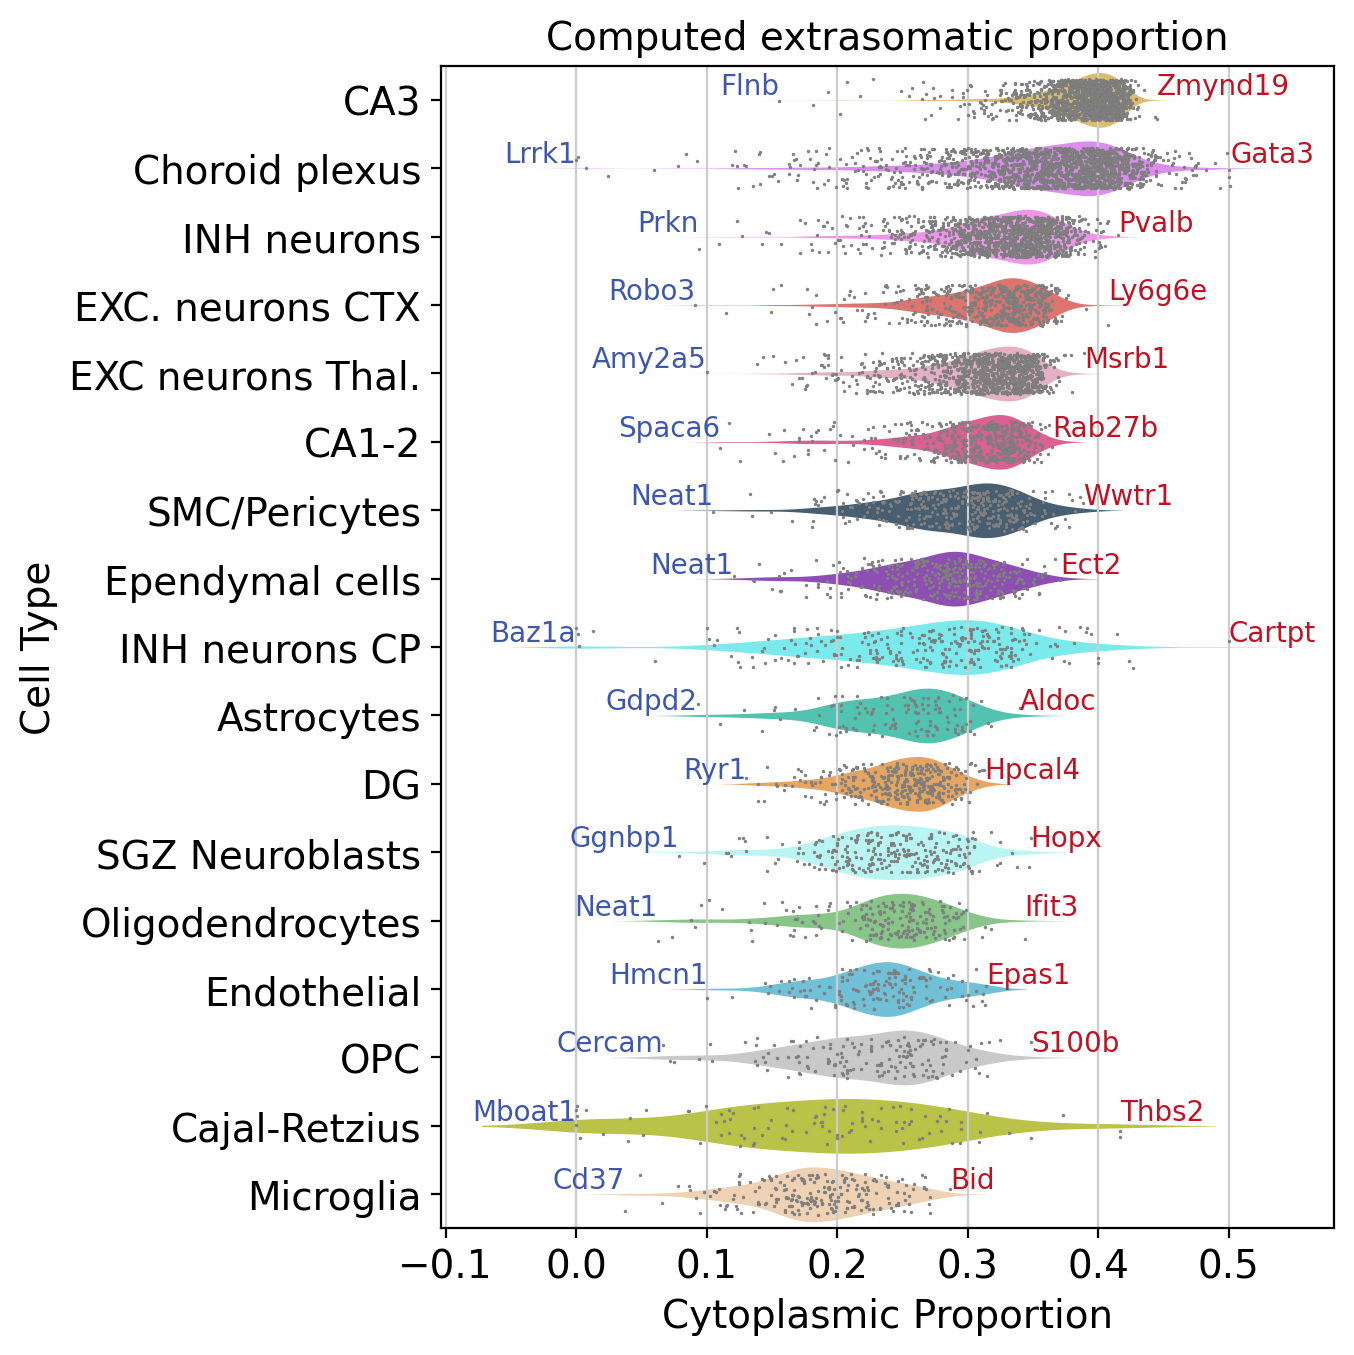

In [76]:


# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')


# Parameters
n = 1  # number of top/bottom genes to label per cell type

# Create the plot
plt.figure(figsize=(7, 7), dpi=100)

ax = sns.violinplot(
    data=filtered_df,
    y='cell_type',
    x='extracellular_proportion',
    order=order_ct,alpha=0.8,linewidth=0,
    palette=cols,
    inner=None
)

sns.stripplot(
    data=filtered_df,
    y='cell_type',
    x='extracellular_proportion',
    color='gray',
    s=1.2,
    order=order_ct,
    jitter=0.3,
    linewidth=0.01,
    ax=ax
)

# Annotate top and bottom n genes for each cell type
for cell_type in order_ct:
    df_sub = filtered_df[filtered_df['cell_type'] == cell_type]

    # Top n
    top_n = df_sub.nlargest(n, 'extracellular_proportion')
    for _, row in top_n.iterrows():
        ax.text(
            row['extracellular_proportion'], cell_type,
            row['gene'],
            color='#bf1324', fontsize=10, va='bottom', ha='left'
        )

    # Bottom n
    bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
    for _, row in bottom_n.iterrows():
        ax.text(
            row['extracellular_proportion'], cell_type,
            row['gene'],
            color='#3d57ad', fontsize=10, va='bottom', ha='right'
        )

plt.xlabel('Cytoplasmic Proportion')
plt.ylabel('Cell Type')
plt.title('Computed extrasomatic proportion')
plt.tight_layout()

plt.savefig(os.path.join(saving_path,'computed_cytoplasm_proportion_violin.pdf'))
plt.show()

# Compare ground truth with inference

In [ ]:
gt_filt=ground_truth_quantification[~ground_truth_quantification['percent_extracellular'].isna()]
gt_filt=gt_filt.reset_index()

# Merge on 'gene' and 'cell_type' with an inner join
merged = pd.merge(gt_filt, filtered_df, on=['gene', 'cell_type'], how='inner',suffixes=('_gt', '_comp'))


We visualize now the **true cytoplasmic proportions** per cell type

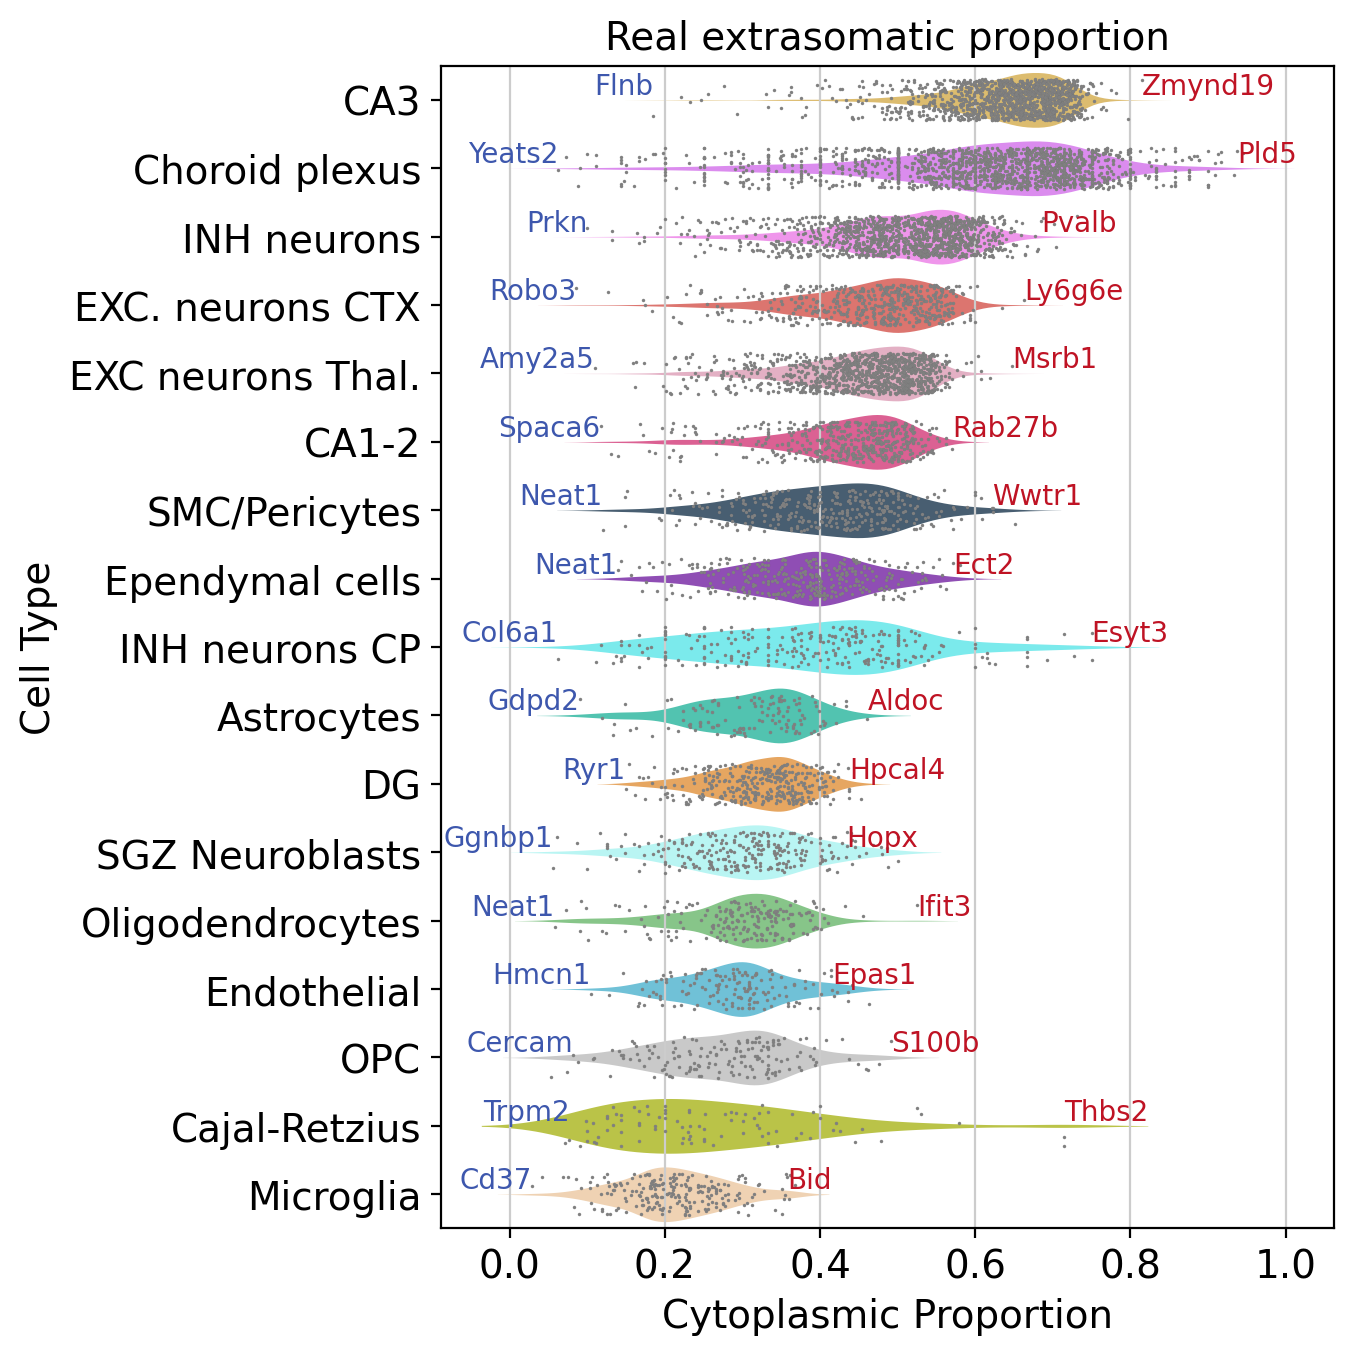

In [80]:
order_ct=filtered_df.loc[:,['cell_type','extracellular_proportion']].groupby('cell_type').mean().sort_values(by='extracellular_proportion',ascending=False).index
cols=[coldict[c] for c in order_ct]

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')


# Parameters
n = 1  # number of top/bottom genes to label per cell type

# Create the plot
plt.figure(figsize=(7, 7), dpi=100)

ax = sns.violinplot(
    data=merged,
    y='cell_type',
    x='percent_extracellular',
    order=order_ct,alpha=0.8,linewidth=0,
    palette=cols,
    inner=None
)

sns.stripplot(
    data=merged,
    y='cell_type',
    x='percent_extracellular',
    color='gray',
    s=1.2,
    order=order_ct,
    jitter=0.3,
    linewidth=0.01,
    ax=ax
)

# Annotate top and bottom n genes for each cell type
for cell_type in order_ct:
    df_sub = merged[merged['cell_type'] == cell_type]

    # Top n
    top_n = df_sub.nlargest(n, 'extracellular_proportion')
    for _, row in top_n.iterrows():
        ax.text(
            row['percent_extracellular'], cell_type,
            row['gene'],
            color='#bf1324', fontsize=10, va='bottom', ha='left'
        )

    # Bottom n
    bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
    for _, row in bottom_n.iterrows():
        ax.text(
            row['percent_extracellular'], cell_type,
            row['gene'],
            color='#3d57ad', fontsize=10, va='bottom', ha='right'
        )

plt.xlabel('Cytoplasmic Proportion')
plt.ylabel('Cell Type')
plt.title('Real extrasomatic proportion')
plt.tight_layout()

plt.savefig(os.path.join(saving_path,'real_cytoplasm_proportion_violin.pdf'))
plt.show()

We plot the **scatter plot** and compute pcc and cosine similarity

In [81]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Prepare data for regression
X = merged['percent_extracellular'].values.reshape(-1, 1)
y = merged['extracellular_proportion'].values

# Fit linear regression
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)

# Extract regression metrics
slope = reg.coef_[0]
intercept = reg.intercept_
r_squared = r2_score(y, y_pred)


In [82]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Prepare data for regression
X = merged['percent_extracellular'].values.reshape(-1, 1)
y = merged['extracellular_proportion'].values

# Fit linear regression
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)

# Extract regression metrics
slope = reg.coef_[0]
intercept = reg.intercept_
r_squared = r2_score(y, y_pred)
print(slope)

0.4347376506337508


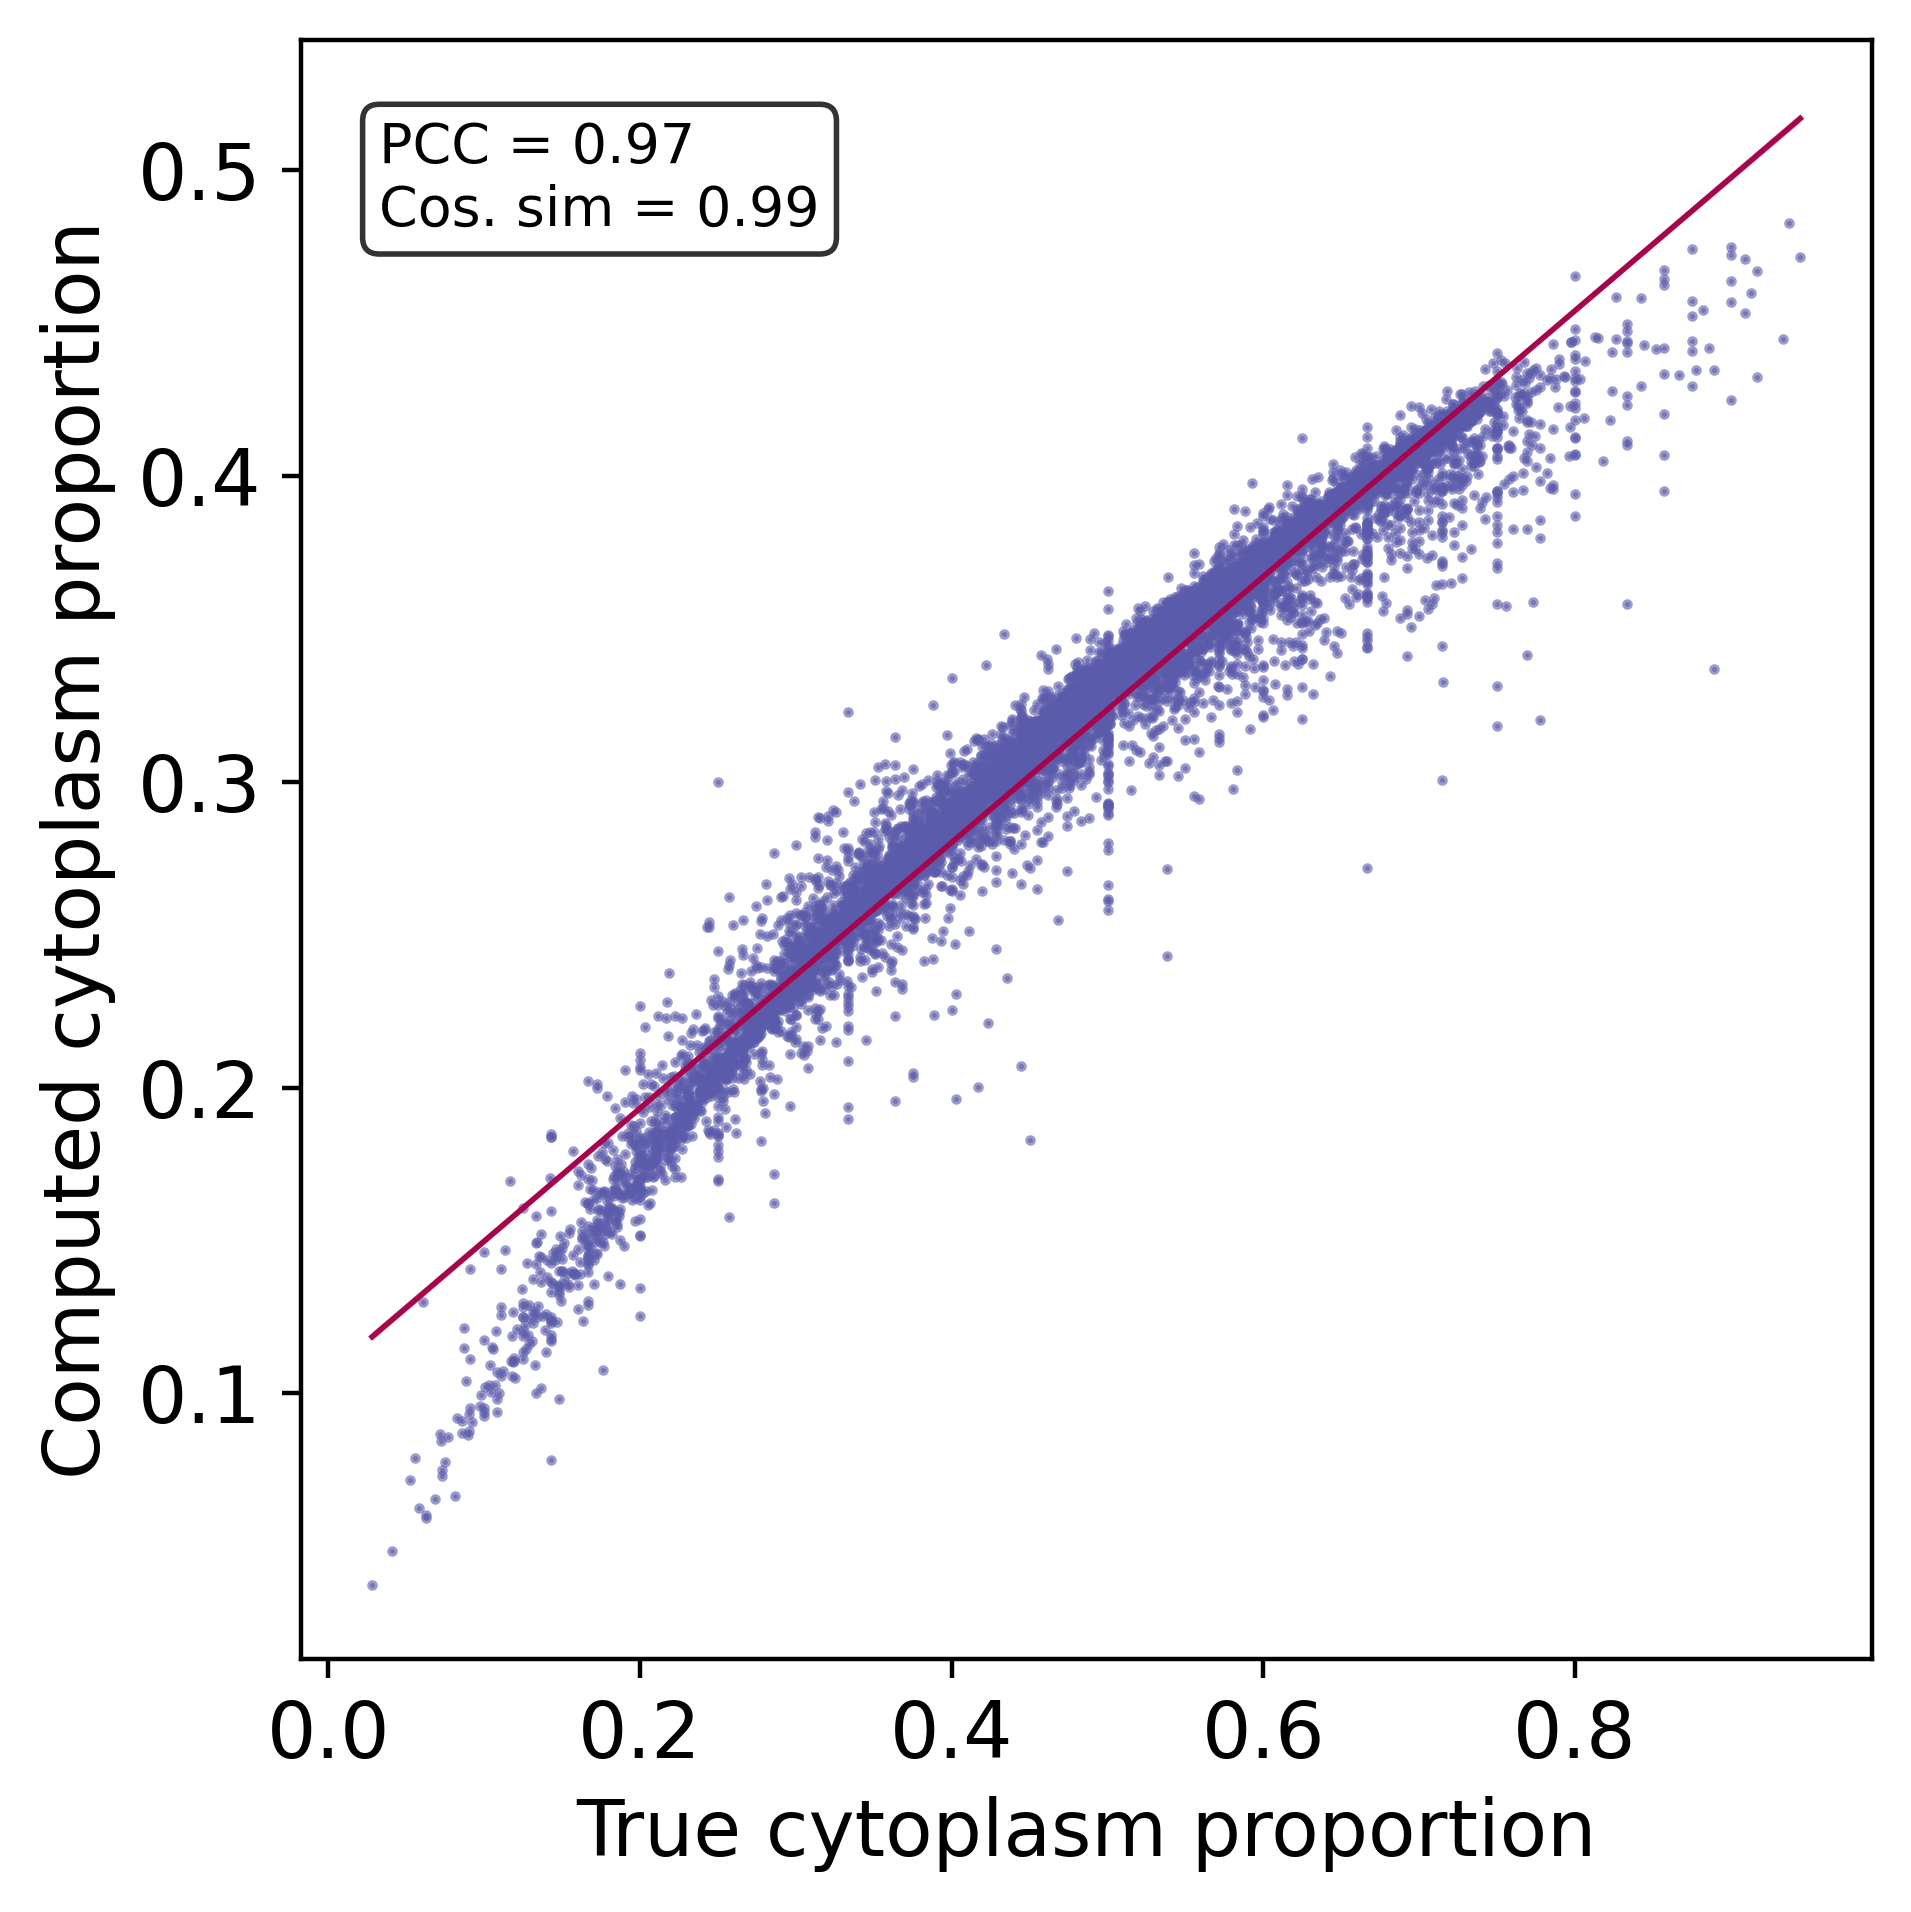

In [70]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')


import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Compute PCC
r, _ = pearsonr(merged['percent_extracellular'], merged['extracellular_proportion'])

# Compute cosine similarity
vec1 = merged['percent_extracellular'].values.reshape(1, -1)
vec2 = merged['extracellular_proportion'].values.reshape(1, -1)
cos_sim = cosine_similarity(vec1, vec2)[0, 0]

# Create the plot
plt.figure(figsize=(5, 5))
sns.regplot(
    x='percent_extracellular',
    y='extracellular_proportion',
    data=merged,
    color='#5b5bab',
    scatter_kws={'s': 0.8, 'alpha': 0.6},
    line_kws={'color': '#a6054b', 'lw': 1}
)

# Annotate with PCC and cosine similarity
plt.text(
    0.05, 0.95,
    f'PCC = {r:.2f}\nCos. sim = {cos_sim:.2f}',
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8)
)

plt.xlabel('True cytoplasm proportion')
plt.ylabel('Computed cytoplasm proportion')
plt.tight_layout()
plt.grid(False)

plt.savefig(os.path.join(saving_path,'true_vs_computed_cytoplasm_proportion.pdf'))
plt.show()
